In [28]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [29]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

In [30]:
class MLP(nn.Module):
  def __init__(self):
    super(MLP, self).__init__()
    self.layer1 = nn.Linear(28 * 28, 256)
    self.layer2 = nn.Linear(256, 128)
    self.layer3 = nn.Linear(128, 10)
    self.relu = nn.ReLU()
  def forward(self, x):
    x = self.layer1(x)
    x = self.relu(x)
    x = self.layer2(x)
    x = self.relu(x)
    x = self.layer3(x)
    return x
douglas = MLP()
douglas.to(device)

MLP(
  (layer1): Linear(in_features=784, out_features=256, bias=True)
  (layer2): Linear(in_features=256, out_features=128, bias=True)
  (layer3): Linear(in_features=128, out_features=10, bias=True)
  (relu): ReLU()
)

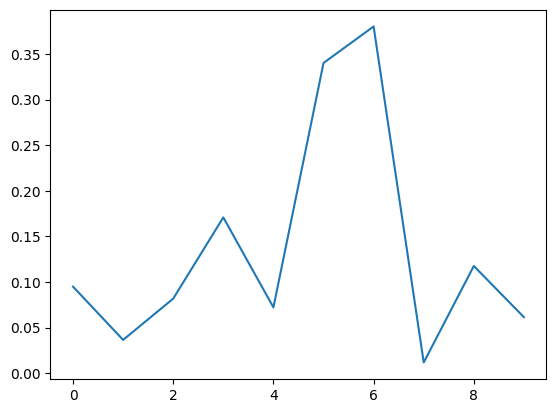

In [31]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(douglas.parameters(), lr=0.01)
erro = []
for i in range(10):
  for image, label in train_loader:
    image = image.view(-1, 28 * 28).to(device)
    label = label.to(device)
    output = douglas.forward(image)
    loss = criterion(output, label)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
  erro.append(loss.item())
plt.plot(erro)
plt.show()
